In [ ]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import balanced_accuracy_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error


In [ ]:
df = pd.read_csv("USvideos.csv")
df

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13T17:13:01.000Z,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...
1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13T07:30:00.000Z,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John..."
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...
3,puqaWrEC7tY,17.14.11,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13T11:00:04.000Z,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...
4,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40944,BZt0qjTWNhw,18.14.06,The Cat Who Caught the Laser,AaronsAnimals,15,2018-05-18T13:00:04.000Z,"aarons animals|""aarons""|""animals""|""cat""|""cats""...",1685609,38160,1385,2657,https://i.ytimg.com/vi/BZt0qjTWNhw/default.jpg,False,False,False,The Cat Who Caught the Laser - Aaron's Animals
40945,1h7KV2sjUWY,18.14.06,True Facts : Ant Mutualism,zefrank1,22,2018-05-18T01:00:06.000Z,[none],1064798,60008,382,3936,https://i.ytimg.com/vi/1h7KV2sjUWY/default.jpg,False,False,False,NaN
40946,D6Oy4LfoqsU,18.14.06,I GAVE SAFIYA NYGAARD A PERFECT HAIR MAKEOVER ...,Brad Mondo,24,2018-05-18T17:34:22.000Z,I gave safiya nygaard a perfect hair makeover ...,1066451,48068,1032,3992,https://i.ytimg.com/vi/D6Oy4LfoqsU/default.jpg,False,False,False,I had so much fun transforming Safiyas hair in...
40947,oV0zkMe1K8s,18.14.06,How Black Panther Should Have Ended,How It Should Have Ended,1,2018-05-17T17:00:04.000Z,"Black Panther|""HISHE""|""Marvel""|""Infinity War""|...",5660813,192957,2846,13088,https://i.ytimg.com/vi/oV0zkMe1K8s/default.jpg,False,False,False,How Black Panther Should Have EndedWatch More ...


In [ ]:
df.shape

(40949, 16)

In [ ]:
df1 = pd.read_json("US_category_id.json")
df1

,kind,etag,items
0,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
1,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
2,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
3,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
4,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
5,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
6,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
7,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
8,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."
9,youtube#videoCategoryListResponse,"""m2yskBQFythfE4irbTIeOgYYfBU/S730Ilt-Fi-emsQJv...","{'kind': 'youtube#videoCategory', 'etag': '""m2..."


In [ ]:
df1.shape

(32, 3)

In [ ]:
# Tipos de datos 
df.info()
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 40949 entries, 0 to 40948
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   video_id                40949 non-null  str  
 1   trending_date           40949 non-null  str  
 2   title                   40949 non-null  str  
 3   channel_title           40949 non-null  str  
 4   category_id             40949 non-null  int64
 5   publish_time            40949 non-null  str  
 6   tags                    40949 non-null  str  
 7   views                   40949 non-null  int64
 8   likes                   40949 non-null  int64
 9   dislikes                40949 non-null  int64
 10  comment_count           40949 non-null  int64
 11  thumbnail_link          40949 non-null  str  
 12  comments_disabled       40949 non-null  bool 
 13  ratings_disabled        40949 non-null  bool 
 14  video_error_or_removed  40949 non-null  bool 
 15  description             40379 

In [ ]:
# Extraer el identificador y el nombre de cada categoría
categorias = pd.DataFrame([
    {
        "category_id": int(item["id"]),
        "categoria": item["snippet"]["title"]
    }
    for item in df1["items"]
])

# Revisar el catálogo resultante
categorias.sort_values("category_id")

,category_id,categoria
0,1,Film & Animation
1,2,Autos & Vehicles
2,10,Music
3,15,Pets & Animals
4,17,Sports
5,18,Short Movies
6,19,Travel & Events
7,20,Gaming
8,21,Videoblogging
9,22,People & Blogs


In [ ]:
df = df.merge(
    categorias,
    on="category_id",
    how="left"
)

In [ ]:
df

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,categoria
0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13T17:13:01.000Z,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...,People & Blogs
1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13T07:30:00.000Z,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John...",Entertainment
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...,Comedy
3,puqaWrEC7tY,17.14.11,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13T11:00:04.000Z,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...,Entertainment
4,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...,Entertainment
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40944,BZt0qjTWNhw,18.14.06,The Cat Who Caught the Laser,AaronsAnimals,15,2018-05-18T13:00:04.000Z,"aarons animals|""aarons""|""animals""|""cat""|""cats""...",1685609,38160,1385,2657,https://i.ytimg.com/vi/BZt0qjTWNhw/default.jpg,False,False,False,The Cat Who Caught the Laser - Aaron's Animals,Pets & Animals
40945,1h7KV2sjUWY,18.14.06,True Facts : Ant Mutualism,zefrank1,22,2018-05-18T01:00:06.000Z,[none],1064798,60008,382,3936,https://i.ytimg.com/vi/1h7KV2sjUWY/default.jpg,False,False,False,NaN,People & Blogs
40946,D6Oy4LfoqsU,18.14.06,I GAVE SAFIYA NYGAARD A PERFECT HAIR MAKEOVER ...,Brad Mondo,24,2018-05-18T17:34:22.000Z,I gave safiya nygaard a perfect hair makeover ...,1066451,48068,1032,3992,https://i.ytimg.com/vi/D6Oy4LfoqsU/default.jpg,False,False,False,I had so much fun transforming Safiyas hair in...,Entertainment
40947,oV0zkMe1K8s,18.14.06,How Black Panther Should Have Ended,How It Should Have Ended,1,2018-05-17T17:00:04.000Z,"Black Panther|""HISHE""|""Marvel""|""Infinity War""|...",5660813,192957,2846,13088,https://i.ytimg.com/vi/oV0zkMe1K8s/default.jpg,False,False,False,How Black Panther Should Have EndedWatch More ...,Film & Animation


In [ ]:
# Valores faltantes por columna
print("Valores faltantes:")
display(df.isnull().sum().sort_values(ascending=False))

# Filas duplicadas exactas
print("Filas duplicadas:", df.duplicated().sum())

# Cantidad de videos únicos
print("Videos únicos:", df["video_id"].nunique())

# Cantidad de categorías
print("Categorías únicas:", df["category_id"].nunique())


Valores faltantes:


description               570
video_id                    0
trending_date               0
channel_title               0
title                       0
publish_time                0
tags                        0
views                       0
category_id                 0
likes                       0
dislikes                    0
thumbnail_link              0
comment_count               0
comments_disabled           0
ratings_disabled            0
video_error_or_removed      0
categoria                   0
dtype: int64

Filas duplicadas: 48
Videos únicos: 6351
Categorías únicas: 16


Análisis de los vídeos sin comentarios (teniendo comentarios habilitados)

In [ ]:
videos_sin_comentarios = df[
    (df["comment_count"] == 0) &
    (df["comments_disabled"] == False)
].copy()

print("Registros sin comentarios:", len(videos_sin_comentarios))
print("Videos únicos:", videos_sin_comentarios["video_id"].nunique())

Registros sin comentarios: 127
Videos únicos: 49


In [ ]:
vídeos_con_comentarios_habilitados = df[
    df["comments_disabled"] == False
]

# Proporción de registros sin comentarios
porcentaje = (
    len(videos_sin_comentarios) / len(vídeos_con_comentarios_habilitados)
) * 100

print(f"Porcentaje de registros sin comentarios: {porcentaje:.2f}%")

Porcentaje de registros sin comentarios: 0.32%


In [ ]:
df["videos_con_comentarios"] = "Vídeos con comentarios"

df.loc[
    (df["comment_count"] == 0) &
    (df["comments_disabled"] == False),
    "videos_con_comentarios"
] = "Vídeos sin comentarios"

# Comparar métricas
comparacion = (
    df[df["comments_disabled"] == False]
    .groupby("videos_con_comentarios")
    .agg(
        registros=("video_id", "size"),
        videos_unicos=("video_id", "nunique"),
        vistas_promedio=("views", "mean"),
        likes_promedio=("likes", "mean"),
        comentarios_promedio=("comment_count", "mean")
    )
    .round(2)
)

comparacion

,registros,videos_unicos,vistas_promedio,likes_promedio,comentarios_promedio
videos_con_comentarios,,,,,
Vídeos con comentarios,40189,6219,2365336.97,75326.47,8606.54
Vídeos sin comentarios,127,49,132900.28,2180.57,0.00


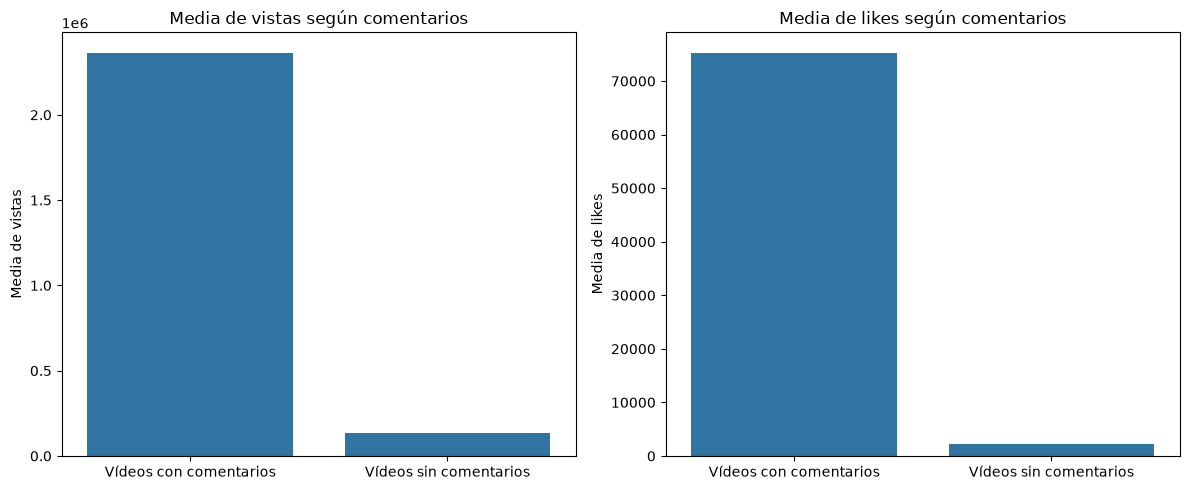

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=df[df["comments_disabled"] == False],
    x="videos_con_comentarios",
    y="views",
    estimator="mean",
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title("Media de vistas según comentarios")
axes[0].set_xlabel("")
axes[0].set_ylabel("Media de vistas")

sns.barplot(
    data=df[df["comments_disabled"] == False],
    x="videos_con_comentarios",
    y="likes",
    estimator="mean",
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title("Media de likes según comentarios")
axes[1].set_xlabel("")
axes[1].set_ylabel("Media de likes")

plt.tight_layout()
plt.show()

In [ ]:
videos_sin_comentarios_categoria = (
    videos_sin_comentarios
    .groupby("categoria")
    .agg(
        registros=("video_id", "size"),
        videos_unicos=("video_id", "nunique"),
        vistas_mediana=("views", "median"),
        likes_mediana=("likes", "median")
    )
    .sort_values("registros", ascending=False)
)

display(videos_sin_comentarios_categoria)

,registros,videos_unicos,vistas_mediana,likes_mediana
categoria,,,,
Entertainment,49,17,2373.0,9.0
People & Blogs,26,9,3244.0,5.5
Sports,15,5,2863.0,2.0
Film & Animation,9,4,26185.0,137.0
Science & Technology,7,3,1425.0,16.0
News & Politics,6,2,4017.0,14.5
Comedy,4,2,5614.0,21.0
Autos & Vehicles,3,1,10270.0,39.0
Music,3,2,2717.0,4.0


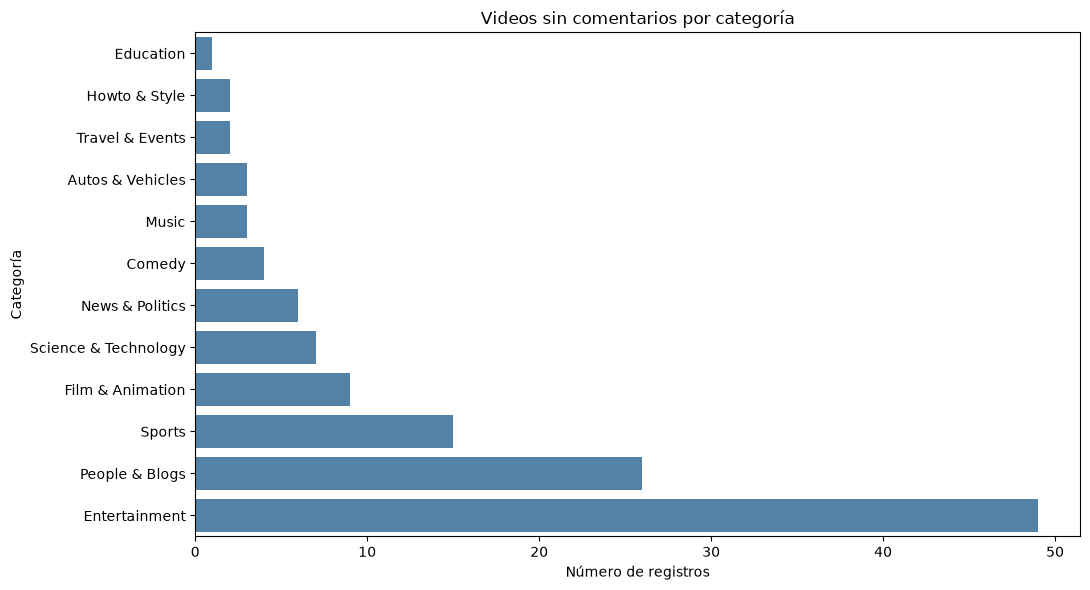

In [ ]:
plt.figure(figsize=(11, 6))

datos = videos_sin_comentarios_categoria.sort_values(
    "registros", ascending=True
)

sns.barplot(
    data=datos.reset_index(),
    x="registros",
    y="categoria",
    color="steelblue"
)

plt.title("Videos sin comentarios por categoría")
plt.xlabel("Número de registros")
plt.ylabel("Categoría")

plt.tight_layout()
plt.show()

¿Cuáles son las categorías de vídeos que reciben mayores vistas y Likes?

In [ ]:
# Conservar un único registro por vídeo
ultimo_registro = (
    df
    .sort_values("trending_date")
    .drop_duplicates(subset="video_id", keep="last")
    .copy()
)



In [ ]:
# Identificar videos sin comentarios, pero con comentarios habilitados
ultimo_registro["sin_comentarios"] = (
    (ultimo_registro["comment_count"] == 0) &
    (~ultimo_registro["comments_disabled"])
)

# Resumen por categoría
resumen_categoria = (
    ultimo_registro.groupby("categoria")
    .agg(
        videos=("video_id", "nunique"),
        vistas_promedio=("views", "mean"),
        vistas_mediana=("views", "median"),
        likes_promedio=("likes", "mean"),
        likes_mediana=("likes", "median"),
        comentarios_habilitados=("comments_disabled", lambda x: (~x).sum()),
        sin_comentarios=("sin_comentarios", "sum")
    )
)

# Porcentaje de videos sin comentarios entre los que los tienen habilitados
resumen_categoria["%_sin_comentarios"] = (
    resumen_categoria["sin_comentarios"] /
    resumen_categoria["comentarios_habilitados"] * 100
)

display(resumen_categoria.round(2))

,videos,vistas_promedio,vistas_mediana,likes_promedio,likes_mediana,comentarios_habilitados,sin_comentarios,%_sin_comentarios
categoria,,,,,,,,
Autos & Vehicles,71,1422994.82,302660.0,10055.97,2504.0,70,1,1.43
Comedy,544,1384955.02,785792.0,54257.63,22360.0,543,2,0.37
Education,251,579469.13,350461.0,20944.12,12202.0,248,1,0.40
Entertainment,1621,1639467.21,580342.0,39895.55,11582.0,1590,13,0.82
Film & Animation,320,2367022.41,764576.5,49858.16,11469.0,316,1,0.32
Gaming,103,2126577.10,1249486.0,65441.58,33506.0,101,0,0.00
Howto & Style,594,882159.31,406893.0,33438.08,15029.5,593,2,0.34
Music,801,5003463.42,976513.0,176199.50,39056.0,799,1,0.13
News & Politics,503,442720.12,170637.0,5834.51,1103.0,470,2,0.43


In [ ]:
top_vistas = resumen_categoria.sort_values(
    "vistas_mediana", ascending=False
).head(10)

top_likes = resumen_categoria.sort_values(
    "likes_mediana", ascending=False
).head(10)

print("TOP 10 - PROMEDIO DE VISTAS")
display(top_vistas[["videos", "vistas_promedio", "vistas_mediana"]].round(2))

print("TOP 10 - PROMEDIO DE LIKES")
display(top_likes[["videos", "likes_promedio", "likes_mediana"]].round(2))

TOP 10 - PROMEDIO DE VISTAS


,videos,vistas_promedio,vistas_mediana
categoria,,,
Gaming,103,2126577.10,1249486.0
Music,801,5003463.42,976513.0
Comedy,544,1384955.02,785792.0
Film & Animation,320,2367022.41,764576.5
Shows,4,752060.75,744843.5
Entertainment,1621,1639467.21,580342.0
Science & Technology,381,1079310.01,424029.0
Howto & Style,594,882159.31,406893.0
Sports,449,1329741.48,401996.0


TOP 10 - PROMEDIO DE LIKES


,videos,likes_promedio,likes_mediana
categoria,,,
Music,801,176199.50,39056.0
Gaming,103,65441.58,33506.0
Comedy,544,54257.63,22360.0
Howto & Style,594,33438.08,15029.5
Shows,4,15369.50,13543.5
People & Blogs,496,45400.47,13107.0
Education,251,20944.12,12202.0
Entertainment,1621,39895.55,11582.0
Film & Animation,320,49858.16,11469.0


De acuerdo a la mediana la categoria con más vistas es la de Gaming mientras que la categoria con más likes es Music

¿Es posible encontrar agrupaciones o clasificaciones de videos?

In [ ]:

# Variables para el agrupamiento
variables = ["views", "likes", "dislikes", "comment_count"]

# Transformación logarítmica y estandarización
X = np.log1p(ultimo_registro[variables])
X_scaled = StandardScaler().fit_transform(X)

# Evaluar diferentes cantidades de grupos
resultados = {}

for k in range(2, 7):
    modelo = KMeans(n_clusters=k)
    etiquetas = modelo.fit_predict(X_scaled)
    resultados[k] = silhouette_score(X_scaled, etiquetas)

# Seleccionar el número de grupos con mejor coeficiente de silueta
mejor_k = max(resultados, key=resultados.get)

# Entrenar modelo final
modelo = KMeans(n_clusters=mejor_k)
ultimo_registro["cluster"] = modelo.fit_predict(X_scaled)

print("Número de grupos seleccionados:", mejor_k)
print("Coeficiente de silueta:", round(resultados[mejor_k], 3))

Número de grupos seleccionados: 2
Coeficiente de silueta: 0.471


Los coeficientes de silueta cercanos a +1 indican que la muestra está lejos de los clústeres vecinos. Un valor de 0 indica que la muestra se encuentra sobre o muy cerca del límite de decisión entre dos clústeres vecinos, y los valores negativos indican que dichas muestras podrían haber sido asignadas al clúster incorrecto, en este caso un coeficiente de silueta de 0.471 indica que la agrupación de videos tiene una calidad intermedia o moderada.

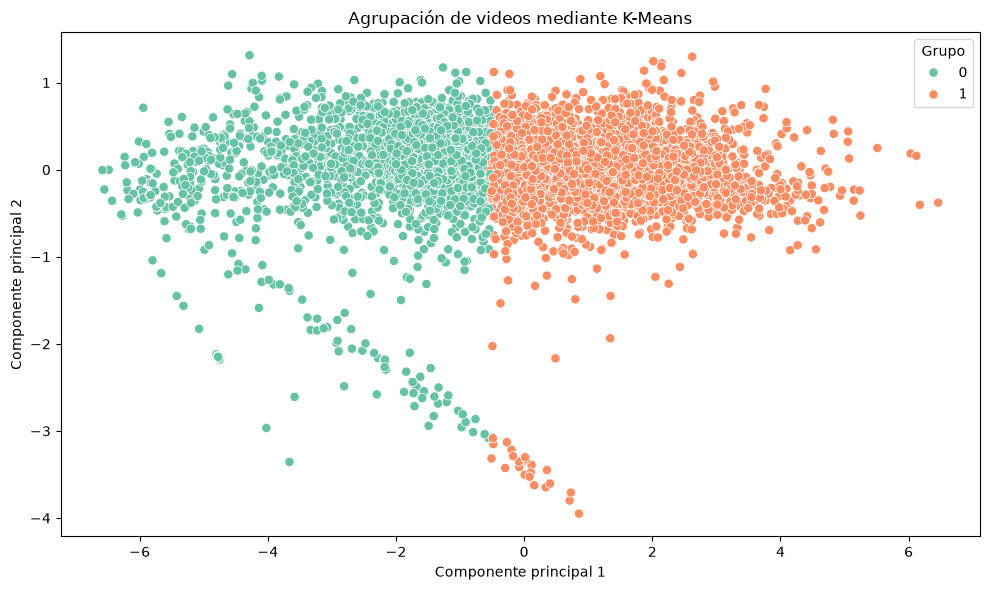

In [ ]:
pca = PCA(n_components=2)
componentes = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=componentes[:, 0],
    y=componentes[:, 1],
    hue=ultimo_registro["cluster"],
    palette="Set2",
    s=45
)

plt.title("Agrupación de videos mediante K-Means")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend(title="Grupo")
plt.tight_layout()
plt.show()

In [ ]:
perfil_clusters = (
    ultimo_registro.groupby("cluster")
    .agg(
        cantidad_videos=("video_id", "nunique"),
        vistas_mediana=("views", "median"),
        likes_mediana=("likes", "median"),
        dislikes_mediana=("dislikes", "median"),
        comentarios_mediana=("comment_count", "median")
    )
    .round(2)
)

display(perfil_clusters)

,cantidad_videos,vistas_mediana,likes_mediana,dislikes_mediana,comentarios_mediana
cluster,,,,,
0,2090,76843.5,1209.5,62.0,188.0
1,4261,954743.0,23976.0,913.0,2571.0


In [ ]:
distribucion = pd.crosstab(
    ultimo_registro["cluster"],
    ultimo_registro["categoria"],
    normalize="index"
) * 100

display(distribucion.round(1))

categoria,Autos & Vehicles,Comedy,Education,Entertainment,Film & Animation,Gaming,Howto & Style,Music,News & Politics,Nonprofits & Activism,People & Blogs,Pets & Animals,Science & Technology,Shows,Sports,Travel & Events
cluster,,,,,,,,,,,,,,,,
0,1.7,5.6,2.6,24.4,5.5,1.1,8.9,8.5,13.7,0.4,7.9,2.7,7.0,0.0,8.8,1.3
1,0.8,10.0,4.6,26.1,4.8,1.9,9.6,14.6,5.1,0.1,7.7,2.0,5.5,0.1,6.2,0.8


De acuerdo a la agrupación con k-means se identifican dos cluster, el primero identificado como cluster 1 contiene los videos de mayor alcance mientras que el cluster 0 tiene videos con métricas inferiores, se evidencia que la categoria de entretenimiento tienen una participación importante.

¿Cuál es la combinación de características o atributos más importantes que hacen de un video tendencia?

In [ ]:
df["publish_time"] = pd.to_datetime(
    df["publish_time"], utc=True, errors="coerce"
)

# Días que duró cada video en tendencias
duracion = (
    df.groupby("video_id")["trending_date"]
    .nunique()
    .rename("dias_tendencia")
)
ultimo_registro = ultimo_registro.merge(duracion, on="video_id")

ultimo_registro["publish_time"] = pd.to_datetime(
    ultimo_registro["publish_time"],
    utc=True,
    errors="coerce"
)


# Crear variables de características
ultimo_registro["longitud_titulo"] = ultimo_registro["title"].str.len()
ultimo_registro["longitud_descripcion"] = ultimo_registro["description"].str.len()
ultimo_registro["cantidad_etiquetas"] = ultimo_registro["tags"].apply(
    lambda x: 0 if pd.isna(x) or x == "[none]" else x.count("|") + 1
)

ultimo_registro["dia_publicacion"] = ultimo_registro["publish_time"].dt.dayofweek
ultimo_registro["mes_publicacion"] = ultimo_registro["publish_time"].dt.month
ultimo_registro["hora_publicacion"] = ultimo_registro["publish_time"].dt.hour

# Definir la variable objetivo
umbral = ultimo_registro["dias_tendencia"].median()

ultimo_registro["tendencia_prolongada"] = (
    ultimo_registro["dias_tendencia"] > umbral
).astype(int)

print("Mediana de días en tendencia:", umbral)
print(ultimo_registro["tendencia_prolongada"].value_counts())

Mediana de días en tendencia: 6.0
tendencia_prolongada
0    3823
1    2528
Name: count, dtype: int64


C:\Users\User\AppData\Local\Temp\ipykernel_23016\2215839780.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  ultimo_registro["dia_publicacion"] = ultimo_registro["publish_time"].dt.dayofweek


In [ ]:
# Variables explicativas
variables = [
    "views", "likes", "comment_count",
    "longitud_titulo", "longitud_descripcion",
    "cantidad_etiquetas", "hora_publicacion",
    "dia_publicacion", "mes_publicacion",
    "categoria", "comments_disabled", "ratings_disabled"
]

X = ultimo_registro[variables]
y = ultimo_registro["tendencia_prolongada"]

# Separar variables numéricas y categóricas
numericas = X.select_dtypes(include="number").columns
categoricas = X.select_dtypes(exclude="number").columns

# Preprocesamiento
preprocesador = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numericas),
    ("cat", Pipeline([
        ("codificar", OneHotEncoder(handle_unknown="ignore"))
    ]), categoricas)
])

# Modelo
modelo = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenamiento y validación
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

modelo.fit(X_train, y_train)

predicciones = modelo.predict(X_test)

print("Exactitud balanceada:",
      round(balanced_accuracy_score(y_test, predicciones), 3))

Exactitud balanceada: 0.753


,importancia
mes_publicacion,0.0927
views,0.0423
likes,0.0207
comment_count,0.0169
hora_publicacion,0.0138
categoria,0.0118
cantidad_etiquetas,0.0116
dia_publicacion,0.0115
longitud_descripcion,0.0077
longitud_titulo,0.0040


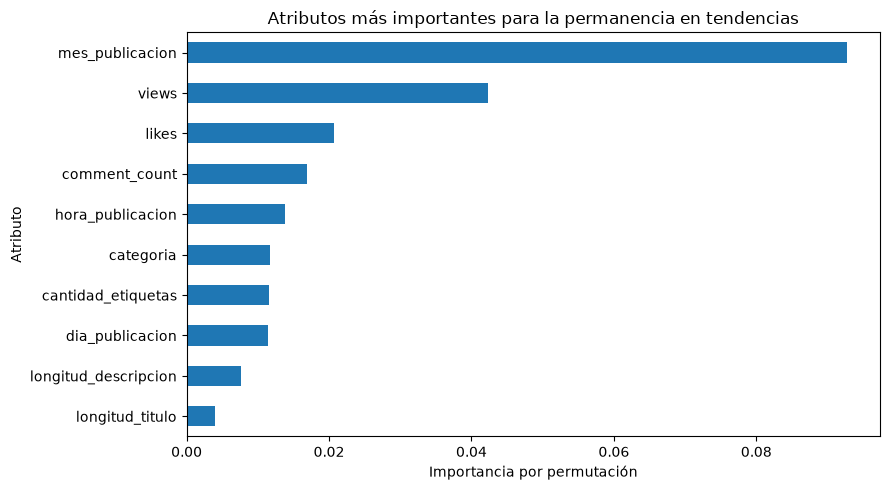

In [ ]:
importancia_de_la_variable = permutation_importance(
    modelo, X_test, y_test,
    n_repeats=10,
    random_state=42,
    scoring="balanced_accuracy",
    n_jobs=-1
)

importancias = pd.Series(
    importancia_de_la_variable.importances_mean,
    index=variables
).sort_values(ascending=False)

display(importancias.to_frame("importancia").round(4))

# Gráfica de los 10 atributos más importantes
importancias.head(10).sort_values().plot(
    kind="barh", figsize=(9, 5)
)

plt.title("Atributos más importantes para la permanencia en tendencias")
plt.xlabel("Importancia por permutación")
plt.ylabel("Atributo")
plt.tight_layout()
plt.show()

Se determinó cuales vídeos tienen una tendencia que se prolonga en el tiempo y para un modelo de Random Forest Classifier se utiliza permutación, una técnica que mide cuánto empeora el desempeño del modelo cuando se altera una variable, por lo tanto se podría suponer que variables pueden influir en que un vídeo esté en tendencia y perdure ahí. "La importancia por permutación es uno de los métodos más robustos y confiables para evaluar la relevancia de las variables, ya que mide el impacto real de cada atributo directamente en el rendimiento final del modelo.
Al desordenar (permutar) los valores de una variable, rompemos su relación con la variable objetivo. Si el modelo empeora drásticamente, significa que esa variable era crucial." De acuerdo a esto se concluye que el mes de publicación es altamente influyente en que un vídeo se mantenga en tendencia

¿La temporada o fecha en el que el video es publicado tiene alguna influencia?

In [ ]:
resumen_mensual = (
    ultimo_registro.groupby("mes_publicacion")
    .agg(
        cantidad_videos=("video_id", "nunique"),
        vistas_mediana=("views", "median"),
        likes_mediana=("likes", "median"),
        dias_tendencia_mediana=("dias_tendencia", "median")
    )
    .round(2)
)

resumen_mensual

,cantidad_videos,vistas_mediana,likes_mediana,dias_tendencia_mediana
mes_publicacion,,,,
1,1269,319454.0,7301.0,5.0
2,995,370450.0,7708.0,7.0
3,688,771141.0,19200.5,10.0
4,536,1095338.0,27270.0,10.0
5,541,1402768.0,34039.0,12.0
6,147,1608741.0,44978.0,5.0
7,4,20093.5,59.0,2.5
8,6,44152.5,86.0,3.0
9,10,10205.5,32.5,3.0


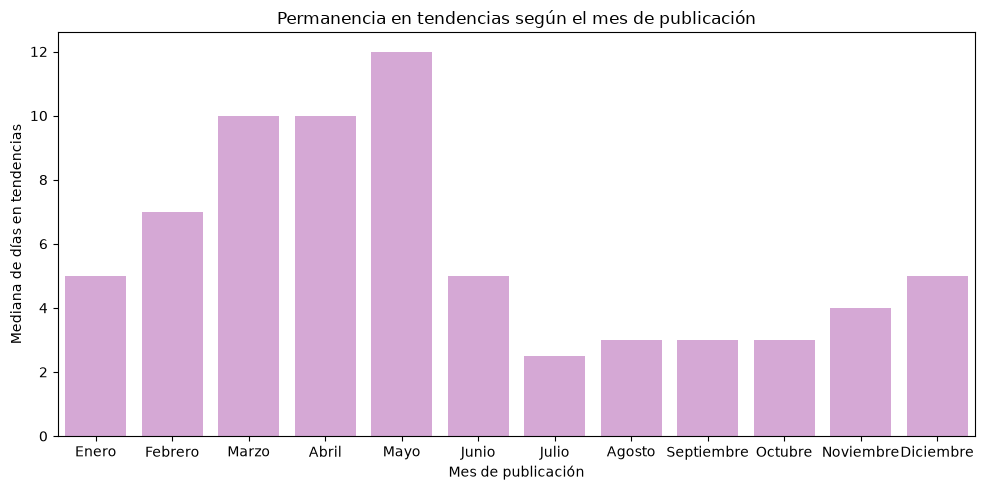

In [ ]:
nombres_meses = [
    "Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", 
    "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"
]
plt.figure(figsize=(10, 5))

sns.barplot(
    data=ultimo_registro,
    x="mes_publicacion",
    y="dias_tendencia",
    estimator="median",
    errorbar=None,
    color="plum"
)
plt.xticks(ticks=range(12), labels=nombres_meses) 
plt.title("Permanencia en tendencias según el mes de publicación")
plt.xlabel("Mes de publicación")
plt.ylabel("Mediana de días en tendencias")
plt.tight_layout()
plt.show()

In [ ]:
# Nombres de los días
dias = {
    0: "Lunes", 1: "Martes", 2: "Miércoles",
    3: "Jueves", 4: "Viernes", 5: "Sábado",
    6: "Domingo"
}

ultimo_registro["nombre_dia"] = ultimo_registro["dia_publicacion"].map(dias)

resumen_dias = (
    ultimo_registro.groupby("nombre_dia")
    .agg(
        cantidad_videos=("video_id", "nunique"),
        vistas_mediana=("views", "median"),
        dias_tendencia_mediana=("dias_tendencia", "median")
    )
    .round(2)
    .sort_values(by="vistas_mediana", ascending=False)
)

resumen_dias

,cantidad_videos,vistas_mediana,dias_tendencia_mediana
nombre_dia,,,
Sábado,547,566512.0,6.0
Jueves,1056,541073.5,6.0
Viernes,1047,539560.0,6.0
Domingo,559,506264.0,5.0
Lunes,985,473026.0,6.0
Miércoles,1097,444366.0,6.0
Martes,1060,431132.5,6.0


In [ ]:
resumen_horas = (
    ultimo_registro.groupby("hora_publicacion")
    .agg(
        cantidad_videos=("video_id", "nunique"),
        vistas_mediana=("views", "median"),
        dias_tendencia_mediana=("dias_tendencia", "median")
    )
    .round(2)
    .sort_values(by="vistas_mediana", ascending=False)
)

display(resumen_horas.sort_values("dias_tendencia_mediana", ascending=False).head(10))

,cantidad_videos,vistas_mediana,dias_tendencia_mediana
hora_publicacion,,,
9,90,910759.0,6.0
4,185,686582.0,6.0
21,296,616733.5,6.0
1,194,569387.0,6.0
17,530,536577.5,6.0
12,204,541647.0,6.0
19,311,502917.0,6.0
15,504,506405.5,6.0
20,327,390261.0,6.0


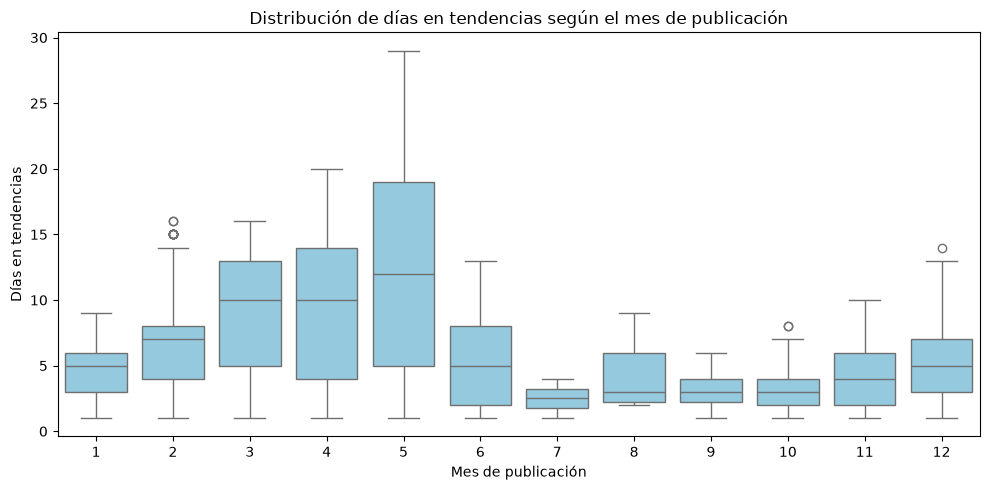

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=ultimo_registro,
    x="mes_publicacion",
    y="dias_tendencia",
    color="SkyBlue"
)

plt.title("Distribución de días en tendencias según el mes de publicación")
plt.xlabel("Mes de publicación")
plt.ylabel("Días en tendencias")

plt.tight_layout()
plt.show()

De acuerdo al análisis realizado mayo es el mes que tiene una mayor mediana de días que los vídeos se mantienen en tendencia, si bien los miércoles tiene mayor número de vídeos, los sábados tienen la mayor mediana de vistas, por lo cual se podría concluir que es un día adecuado para publicar vídeos.

¿Es posible predecir cuantos likes o visitas tendrá un video? Si es así, crea un modelo que lo compruebe.

In [ ]:
# Longitud del título
ultimo_registro["longitud_titulo"] = ultimo_registro["title"].str.len()

# Número de etiquetas
ultimo_registro["num_tags"] = (
    ultimo_registro["tags"]
    .fillna("")
    .apply(lambda x: 0 if x == "[none]" else len(x.split("|")))
)

# Hora de publicación
ultimo_registro["publish_time"] = pd.to_datetime(ultimo_registro["publish_time"])
ultimo_registro["publish_hour"] = ultimo_registro["publish_time"].dt.hour

# Día de la semana
ultimo_registro["publish_day"] = ultimo_registro["publish_time"].dt.dayofweek



C:\Users\User\AppData\Local\Temp\ipykernel_23016\2729181761.py:16: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  ultimo_registro["publish_day"] = ultimo_registro["publish_time"].dt.dayofweek


In [ ]:
X = ultimo_registro[
    [
        "category_id",
        "longitud_titulo",
        "num_tags",
        "publish_hour",
        "publish_day"
    ]
]

y = np.log1p(ultimo_registro["views"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         ["category_id"])
    ],
    remainder="passthrough"
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("R² =", round(r2_score(y_test, y_pred),3))

R² = 0.118


Se utilizó un modelo random forest para saber si era posible predecir el número de vistas, sin embargo, al evaluarlo, se identifica que no es un buen modelo para predecir esto, al menos las variables consideradas, puede ser que el éxito de los vídeos dependa de otras variables 